# LeiData 014845: dictionary from matrix-profile motifs

`python -m analysis.dict_learning.code.learn.learn_from_motifs` on the whitened spectrogram `GPL_Python` wrote for `SOCAL_H_76_230427_014845.x.wav`.

Each column is one STFT hop (0.12288 s at 200 kHz). The search uses every frequency bin from 10 Hz to 10 kHz. Each round takes the stronger of a 5 s and a 10 s motif, adds that rectangle, and refines the dictionary. The loop stops when the detection map covers half the frames.


In [1]:
%matplotlib inline

import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

REPO = Path("/home/yfreund/projects/panMP_whales")
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

from analysis.dict_learning.code.io import stitch_whitened_spectrogram
from analysis.matrix_profile import format_clock

OUT = Path(
    "/home/yfreund/whale_processing/result/LeiData/"
    "dict_learning_templates/014845_gpl_learn_from_motifs"
)
GPL_DIR = Path.home() / "whale_processing/result/LeiData/SOCAL_H_76_230427_014845.x.gpl/output"

summary = json.loads((OUT / "summary.json").read_text())
matchings = json.loads((OUT / "matchings.json").read_text())
detection = np.load(OUT / "detection_map.npy")
templates = [
    (int(path.stem.split("_")[1]), np.load(path))
    for path in sorted(OUT.glob("template_*.npy"))
]
SEC_PER_BIN = float(summary["sec_per_bin"])
START_FREQ = float(summary["start_freq"])
END_FREQ = float(summary["end_freq"])
n_frames = detection.size
duration_s = n_frames * SEC_PER_BIN

print(f"OUT: {OUT}")
print(
    f"frames={n_frames}  duration={duration_s:.0f} s  hop={SEC_PER_BIN:.5f} s  "
    f"atoms={len(templates)}  matchings={len(matchings)}"
)


OUT: /home/yfreund/whale_processing/result/LeiData/dict_learning_templates/014845_10kHz_learn_from_motifs
frames=9000  duration=2250 s  atoms=3  matchings=305


## Run summary

In [2]:
round_rows = []
for item in summary["rounds"]:
    round_rows.append(
        f"| {item['length_s']:g} | {item['width']} | "
        f"{format_clock(item['start_a'] * SEC_PER_BIN)} | "
        f"{format_clock(item['start_b'] * SEC_PER_BIN)} | "
        f"{(item['start_b'] - item['start_a']) * SEC_PER_BIN:.1f} | "
        f"{item['distance']:.2f} | {item['coverage']:.3f} |"
    )

lines = [
    "| | |",
    "|---|---|",
    "| Spectrogram | GPL whitened `spwhiten` |",
    f"| Frequency | {START_FREQ:.0f}–{END_FREQ:.0f} Hz |",
    f"| Duration | {duration_s / 60:.1f} min, hop {SEC_PER_BIN:.5f} s |",
    f"| Stop | `{summary['stop_reason']}` (target 0.5) |",
    f"| Coverage | {summary['coverage']:.3f} |",
    f"| Match threshold | {summary['max_relative_distance']} unexplained energy |",
    f"| Atoms | {summary['n_atoms']} |",
    f"| Matchings | {summary['n_matchings']} |",
    "",
    "| length (s) | width (frames) | copy A | copy B | separation (s) | distance | coverage |",
    "|---:|---:|---:|---:|---:|---:|---:|",
    *round_rows,
]
display(Markdown("\n".join(lines)))


| | |
|---|---|
| WAV | `SOCAL_H_76_230427_014845.x_10kHz.wav` |
| Duration | 37.5 min at 4 frames/s |
| Stop | `coverage` (target 0.5) |
| Coverage | 0.678 |
| Match threshold | 0.00165 unexplained energy |
| Atoms | 3 |
| Matchings | 305 |

| length (s) | width (frames) | copy A | copy B | separation (s) | distance | coverage |
|---:|---:|---:|---:|---:|---:|---:|
| 5 | 20 | 34:01.0 | 34:24.5 | 23.5 | 4.60 | 0.191 |
| 5 | 20 | 28:49.0 | 31:47.8 | 178.8 | 0.49 | 0.402 |
| 5 | 20 | 29:55.2 | 30:31.2 | 36.0 | 1.01 | 0.678 |

## The atoms

Each panel is one learned atom on the whitened spectrogram. Color is log energy.


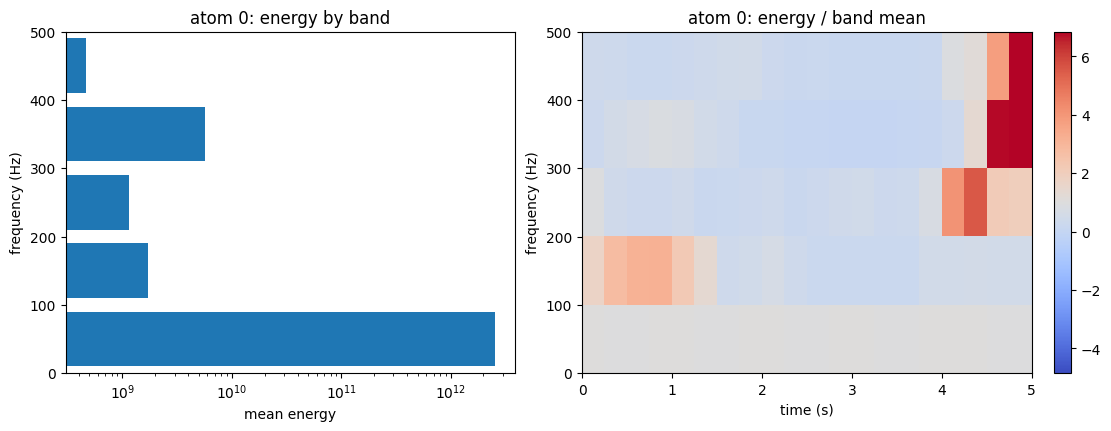

atom 0: 5 s, covers 0.191 of the frames, 99.6% of its energy is in 0–100 Hz


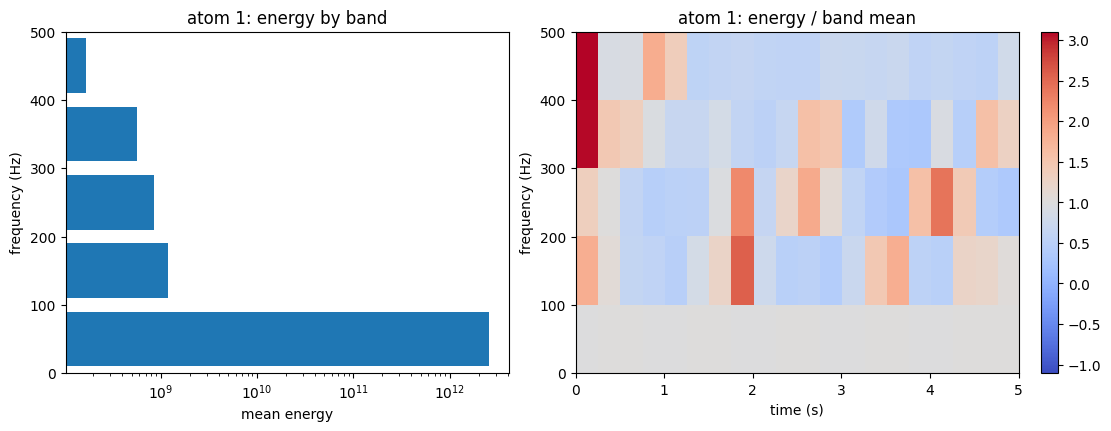

atom 1: 5 s, covers 0.484 of the frames, 99.9% of its energy is in 0–100 Hz


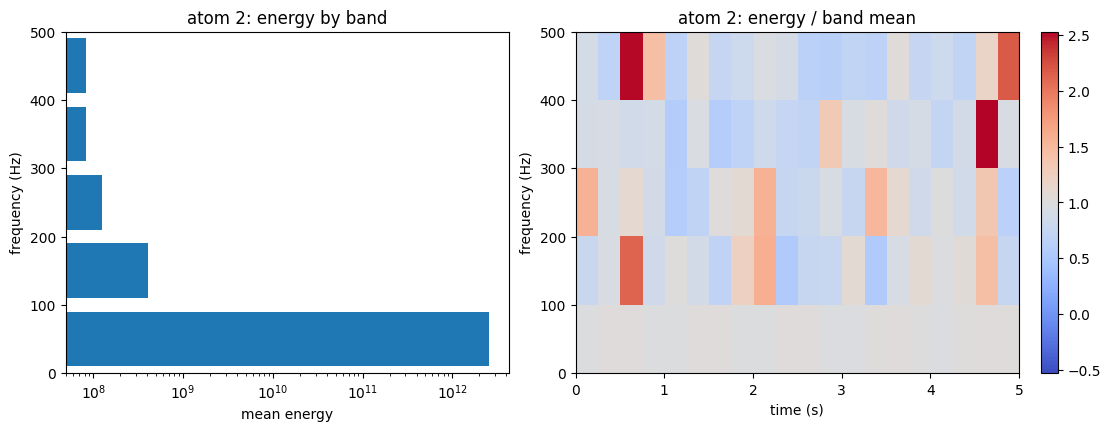

atom 2: 5 s, covers 0.002 of the frames, 100.0% of its energy is in 0–100 Hz


In [3]:
for template_id, data in templates:
    duration = data.shape[1] * SEC_PER_BIN
    covered = float(np.mean(detection == template_id))
    fig, ax = plt.subplots(figsize=(6.5, 3.6), layout="constrained")
    image = ax.imshow(
        np.log10(data + 1e-6),
        origin="lower",
        aspect="auto",
        cmap="magma",
        extent=[0, duration, START_FREQ, END_FREQ],
    )
    ax.set_xlabel("time (s)")
    ax.set_ylabel("frequency (Hz)")
    ax.set_title(f"atom {template_id}: {duration:.1f} s, covers {covered:.3f} of the frames")
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04, label="log10 energy")
    plt.show()


## Where it was placed

The detection map labels each frame with a template id, or −1 where nothing matched. Coverage is the fraction of frames that are labeled.


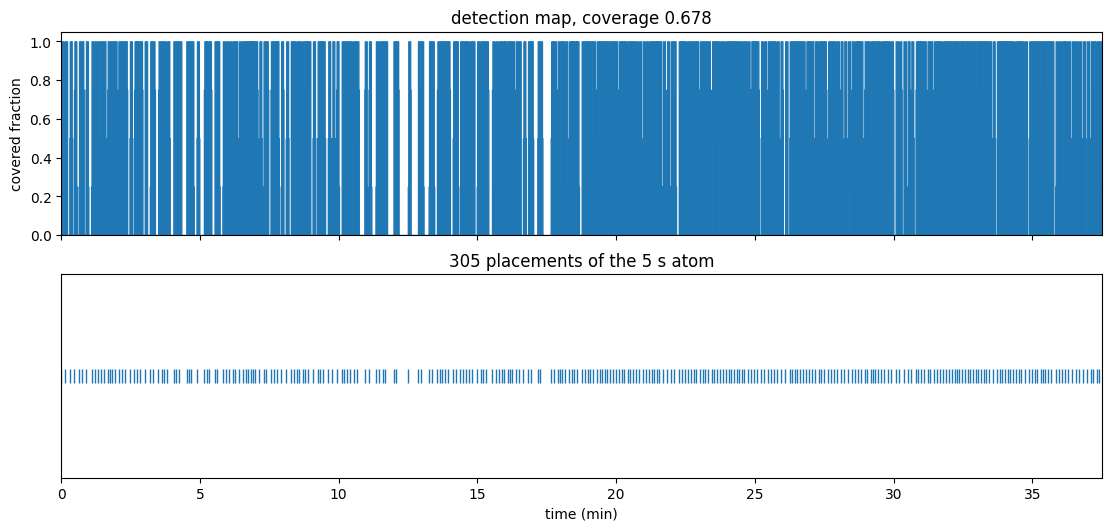

gap between placement starts: min 5.0 s, median 6.5 s, max 26.0 s


In [4]:
covered = detection >= 0
bin_w = max(1, int(round(1.0 / SEC_PER_BIN)))
n_use = (covered.size // bin_w) * bin_w
per_second = covered[:n_use].reshape(-1, bin_w).mean(axis=1)
minutes = np.arange(per_second.size) * bin_w * SEC_PER_BIN / 60

starts = np.array([m["t_start"] for m in matchings], dtype=float) * SEC_PER_BIN
order = np.argsort(starts)
starts = starts[order]
gaps = np.diff(starts)

fig, axes = plt.subplots(2, 1, figsize=(11, 5.2), layout="constrained", sharex=True)
axes[0].fill_between(minutes, per_second, step="mid", color="C0")
axes[0].set_ylabel("covered fraction")
axes[0].set_ylim(0, 1.05)
axes[0].set_title(f"detection map, coverage {summary['coverage']:.3f}")
axes[1].plot(starts / 60, np.zeros_like(starts), "|", color="C0", markersize=10)
axes[1].set_xlabel("time (min)")
axes[1].set_yticks([])
length_s = summary["rounds"][0]["length_s"]
axes[1].set_title(f"{len(starts)} placements")
axes[1].set_xlim(0, duration_s / 60)
plt.show()

if gaps.size:
    print(
        f"gap between placement starts: "
        f"min {gaps.min():.1f} s, median {np.median(gaps):.1f} s, max {gaps.max():.1f} s"
    )


## The two copies that seeded the first motif

The matrix profile found these two stretches on the whitened spectrogram. The dictionary atom is that pair after refinement.


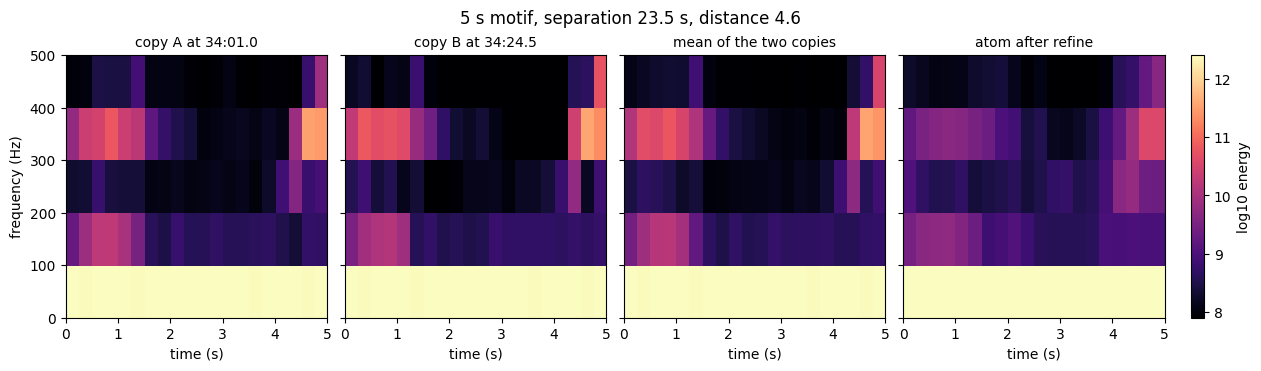

In [5]:
profile = stitch_whitened_spectrogram(GPL_DIR).data
seed = summary["rounds"][0]
width = int(seed["width"])
crops = [profile[:, int(seed[key]) : int(seed[key]) + width] for key in ("start_a", "start_b")]
pair_mean = 0.5 * (crops[0] + crops[1])
learned = templates[0][1]
panels = [
    (crops[0], f"copy A at {format_clock(seed['start_a'] * SEC_PER_BIN)}"),
    (crops[1], f"copy B at {format_clock(seed['start_b'] * SEC_PER_BIN)}"),
    (pair_mean, "mean of the two copies"),
    (learned, "atom after refine"),
]
logged = [np.log10(np.asarray(data, dtype=np.float64) + 1e-6) for data, _ in panels]
flat = np.concatenate([panel.ravel() for panel in logged])
vmin, vmax = np.percentile(flat, [5, 99])
fig, axes = plt.subplots(1, 4, figsize=(12.5, 3.6), layout="constrained", sharey=True)
image = None
for ax, data, (_, title) in zip(axes, logged, panels):
    image = ax.imshow(
        data,
        origin="lower",
        aspect="auto",
        cmap="magma",
        extent=[0, width * SEC_PER_BIN, START_FREQ, END_FREQ],
        vmin=vmin,
        vmax=vmax,
    )
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("time (s)")
axes[0].set_ylabel("frequency (Hz)")
fig.colorbar(image, ax=axes.tolist(), fraction=0.02, pad=0.02, label="log10 energy")
fig.suptitle(
    f"{seed['length_s']:g} s motif, "
    f"separation {(seed['start_b'] - seed['start_a']) * SEC_PER_BIN:.1f} s, "
    f"distance {seed['distance']:.1f}"
)
plt.show()
